# CRISP-ML(Q) Phase 6 – Monitoring and Maintenance

**Goal:** a deployed model gets worse when the world changes: arbovirus circulation moves between states and years, and the
mix of diseases shifts. This phase defines **what to watch**, **how to measure it** and **when to retrain**.

Code: `src/monitoring.py` (`python -m src.monitoring` saves `models/monitoring.json`, shown on `/methodology/6`).

Previous phase: `05_deployment.ipynb`

## 6.1 What we monitor

| Signal | Question | Measure | Retraining rule |
|---|---|---|---|
| Data drift | Do new patients look like the training patients? | PSI of every feature | PSI > 0.25 in a top-5 SHAP feature |
| Prior drift | Has the mix of diseases changed? | Share of each lab-confirmed diagnosis | Change > 5 percentage points |
| Performance drift | Does the model still meet the success criteria? | Macro ROC-AUC on newly labeled cases | Below 0.80 |

The **Population Stability Index** compares two distributions bin by bin:
PSI = Σ (current% − reference%) · ln(current% / reference%). Usual reading: < 0.10 stable, 0.10–0.25 moderate, > 0.25 significant.

As a realistic test we monitor the model trained on **2023** with the surveillance data of **2025**.

In [1]:
import sys
sys.path.insert(0, "..")  # project root, to import the src package

import matplotlib.pyplot as plt
import pandas as pd

from src.monitoring import PSI_MODERATE, PSI_SIGNIFICANT, build_report

pd.set_option("display.precision", 3)
report = build_report(save=False)
print(f"Reference year {report['reference_year']} -> current year {report['current_year']}")

Reference year 2023 -> current year 2025


## 6.2 Data drift (PSI per feature)

,label,psi,status,reference,current
0,State of residence,1.389,significant,NaN,NaN
1,Month of consultation,0.112,moderate,NaN,NaN
2,Muscle pain,0.015,stable,0.737,0.788
3,Headache,0.010,stable,0.707,0.752
4,Nausea,0.008,stable,0.344,0.387
5,Hypertension,0.007,stable,0.103,0.131
6,Fever,0.007,stable,0.797,0.830
7,Diabetes,0.005,stable,0.045,0.060


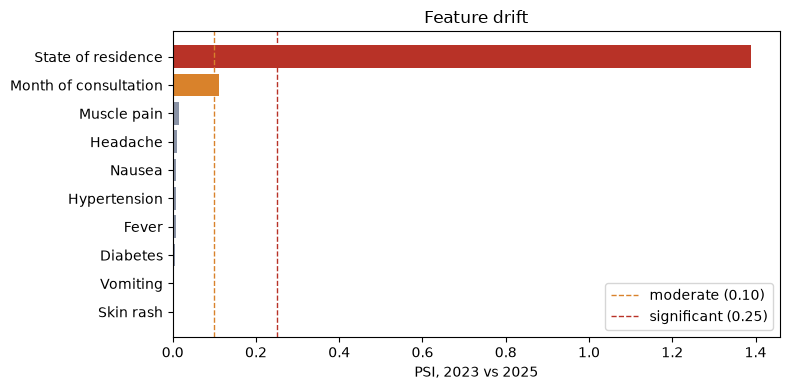

In [2]:
drift = pd.DataFrame(report["data_drift"])
display(drift[["label", "psi", "status", "reference", "current"]].head(8))

top = drift.head(10).iloc[::-1]
colors = ["#b83227" if s == "significant" else "#d9822b" if s == "moderate" else "#8a93a6" for s in top["status"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top["label"], top["psi"], color=colors)
ax.axvline(PSI_MODERATE, color="#d9822b", ls="--", lw=1, label="moderate (0.10)")
ax.axvline(PSI_SIGNIFICANT, color="#b83227", ls="--", lw=1, label="significant (0.25)")
ax.set_xlabel("PSI, 2023 vs 2025"); ax.set_title("Feature drift"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Reading:** symptoms, findings and comorbidities are stable: patients present the same way. The large change is in
**state of residence**: the states where lab-confirmed cases come from moved between 2023 and 2025, and the **month**
changes moderately (different season timing). State of residence is the most important feature (SHAP), so this drift hits the
model where it matters most.

## 6.3 Prior drift (mix of diagnoses)

In [3]:
priors = pd.DataFrame(report["prior_drift"])
priors[["reference", "current", "change"]] = (priors[["reference", "current", "change"]] * 100).round(1)
priors.columns = ["class", f"{report['reference_year']} (%)", f"{report['current_year']} (%)", "change (pp)"]
priors

,class,2023 (%),2025 (%),change (pp)
0,dengue,85.1,77.4,-7.7
1,chikungunya,7.3,9.7,2.4
2,other_febrile,7.6,12.9,5.3


## 6.4 Performance drift

In [4]:
perf = report["performance"]
print(f"Macro ROC-AUC: test {report['reference_year']} = {perf['reference']:.2f}  ->  {report['current_year']} = {perf['current']:.2f}")
pd.DataFrame(perf["per_class"])[["label", "roc_auc", "recall"]]

Macro ROC-AUC: test 2023 = 0.86  ->  2025 = 0.76


,label,roc_auc,recall
0,Dengue,0.810,0.866
1,Chikungunya,0.708,0.212
2,Other febrile illness,0.763,0.550


## 6.5 Retraining decision

In [5]:
for r in report["decision"]["rules"]:
    print(("FIRED  " if r["fired"] else "ok     ") + f"{r['rule']}  ->  {r['value']}")
print("\nDecision:", "RETRAIN the model" if report["decision"]["retrain"] else "keep the current model")

FIRED  Macro ROC-AUC on new data below 0.80  ->  0.76
FIRED  Significant drift (PSI > 0.25) in one of the top-5 SHAP features  ->  State of residence
FIRED  Share of a diagnosis changes by more than 5 percentage points  ->  dengue, other_febrile

Decision: RETRAIN the model


## 6.6 Maintenance plan

- **Retrain** when a rule fires, and at least once a year: `python -m src.sinan --years <train> <validation>`, then
  `python -m src.train` and `python -m src.monitoring`.
- **Retrain on recent data:** the 2025 drift is mostly geographic and seasonal, so the newest year should be part of training.
- **Close the loop:** store the laboratory result of each consultation in the app, so the hospital builds its own labeled
  dataset (with numeric lab values) and the performance rule can be checked on local patients.
- **Colombia:** the external validation (Tuluá, ROC-AUC 0.56) shows the model must be retrained with Colombian data before
  use there.
- **Keep the notice:** clinical decision support only.

The CRISP-ML(Q) cycle closes here: monitoring results send the project back to Phase 1 or 2 for the next iteration.